# La curva nominal mexicana: estructura y pronóstico
**Ejercicio Junior Statistician · Tukan** · Iker Bali Elizalde · octubre de 2026

Este notebook reproduce todo el análisis en el mismo orden que la presentación:

1. Formato de los datos (de formato largo a formato ancho)
2. EDA: gráficas, valores faltantes y matriz de correlación
3. Imputación: comparación de MICE, KNN e interpolación lineal
4. Análisis de componentes principales (PCA)
5. Dos enfoques: individual (9 series) y colectivo (3 componentes)
6. Modelos: Holt, ARIMA y regresión Ridge
7. Evaluación: backtest con ventana expandible, RMSE, MAE y prueba de Diebold-Mariano
8. Resultados por enfoque y por plazo
9. Pronóstico final a 3 y 12 meses

**Requisitos:** `numpy`, `pandas`, `scipy`, `scikit-learn`, `statsmodels`, `matplotlib`, `joblib`. El archivo `banxico_auction_rates_monthly.csv` debe estar en la misma carpeta. El backtest completo tarda unos minutos.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from joblib import Parallel, delayed
from sklearn.impute import KNNImputer
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.linear_model import RidgeCV
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .3})

ORDER = ["CETEs, 28 days", "CETEs, 91 days", "CETEs, 182 days", "CETEs, 364 days",
         "MBONOs, 3 years", "MBONOs, 5 years", "MBONOs, 10 years", "MBONOs, 20 years", "MBONOs, 30 years"]
S = ["C28", "C91", "C182", "C364", "M3", "M5", "M10", "M20", "M30"]   # nombres cortos
LAB = ["28d", "91d", "182d", "364d", "3a", "5a", "10a", "20a", "30a"]
CETES, MBONOS = S[:4], S[4:]
FIRST_ORIGIN = 95      # septiembre de 2014: 96 meses de historia antes del primer pronóstico
H = [3, 12]            # un trimestre y cuatro trimestres
BLUE, ORANGE, GREEN, RED = "#2a78d6", "#eb6834", "#1baf7a", "#d0312d"

## Paso 1 · Formato de los datos
El archivo viene en **formato largo**: una fila por observación (fecha, instrumento, valor), con los 9 plazos mezclados en una sola columna. Lo convierto a **formato ancho**: una fila por mes y una columna por plazo, que es la forma que necesitan la correlación, el PCA y los modelos.

In [2]:
largo = pd.read_csv("banxico_auction_rates_monthly.csv", parse_dates=["DATE"])
print("Formato largo:", largo.shape)
display(largo.head())

# validaciones: sin duplicados mes-instrumento y calendario mensual completo
assert not largo.duplicated(["DATE", "INSTRUMENT"]).any()

W = largo.pivot(index="DATE", columns="INSTRUMENT", values="VALUE_PCT")[ORDER]
W.columns = S
W = W.asfreq("MS")                     # calendario mensual completo (los meses sin subasta quedan como NaN)
X = W.values
print("Formato ancho:", W.shape, "| de", W.index[0].date(), "a", W.index[-1].date())
display(W.head())

Formato largo: (1936, 4)


,DATE,INSTRUMENT,INDICATOR,VALUE_PCT
0,2006-10-01,"CETEs, 182 days",Annualized monthly average rate,7.42
1,2006-10-01,"CETEs, 28 days",Annualized monthly average rate,7.05
2,2006-10-01,"CETEs, 364 days",Annualized monthly average rate,7.50
3,2006-10-01,"CETEs, 91 days",Annualized monthly average rate,7.21
4,2006-10-01,"MBONOs, 10 years",Annualized monthly average rate,8.40


Formato ancho: (240, 9) | de 2006-10-01 a 2026-09-01


,C28,C91,C182,C364,M3,M5,M10,M20,M30
DATE,,,,,,,,,
2006-10-01,7.05,7.21,7.42,7.50,7.62,7.88,8.40,NaN,8.08
2006-11-01,7.04,7.16,7.26,7.28,7.39,7.50,7.88,7.95,NaN
2006-12-01,7.04,7.16,7.20,7.27,7.18,7.28,7.56,7.57,NaN
2007-01-01,7.04,7.19,7.31,7.46,7.70,7.52,7.43,7.93,NaN
2007-02-01,7.04,7.19,7.34,7.38,7.47,7.70,7.96,NaN,7.71


## Paso 2 · EDA
### 2.1 Gráfica de ambos instrumentos

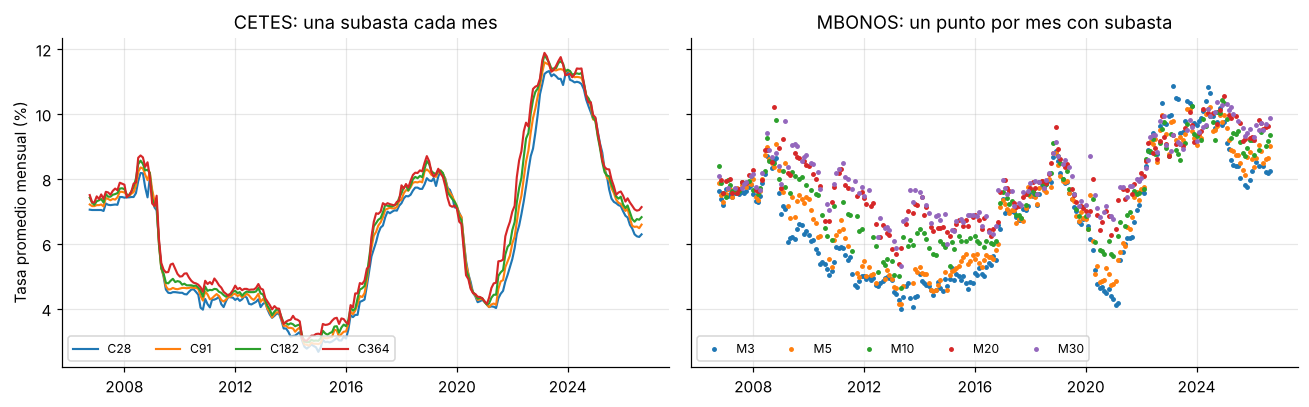

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for s in CETES:
    ax[0].plot(W.index, W[s], lw=1.4, label=s)
for s in MBONOS:
    ax[1].plot(W.index, W[s], lw=0, marker="o", ms=2.2, label=s)
ax[0].set_title("CETES: una subasta cada mes"); ax[1].set_title("MBONOS: un punto por mes con subasta")
ax[0].set_ylabel("Tasa promedio mensual (%)")
for a in ax: a.legend(ncol=5, fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

### 2.2 Porcentaje de valores faltantes

In [4]:
falt = pd.DataFrame({"meses sin dato": W.isna().sum(), "% faltante": (100 * W.isna().mean()).round(1)})
display(falt.T)
print(f"Total: {int(W.isna().sum().sum())} de {W.size} celdas = {100 * W.isna().values.mean():.2f}%")
print("Meses con las nueve tasas:", int(W.notna().all(axis=1).sum()), "de", len(W))

# racha máxima de meses seguidos sin dato por serie
racha = {s: int(W[s].isna().astype(int).groupby(W[s].notna().cumsum()).sum().max()) for s in S}
print("Racha máxima sin dato:", racha)

,C28,C91,C182,C364,M3,M5,M10,M20,M30
meses sin dato,0.0,0.0,0.0,0.0,4.0,16.0,63.0,69.0,72.0
% faltante,0.0,0.0,0.0,0.0,1.7,6.7,26.2,28.7,30.0


Total: 224 de 2160 celdas = 10.37%
Meses con las nueve tasas: 40 de 240
Racha máxima sin dato: {'C28': 0, 'C91': 0, 'C182': 0, 'C364': 0, 'M3': 1, 'M5': 3, 'M10': 4, 'M20': 3, 'M30': 3}


### 2.3 Matriz de correlación
Se calcula por parejas: cada celda usa los meses en que ambas series tienen dato, así que admite los valores faltantes.

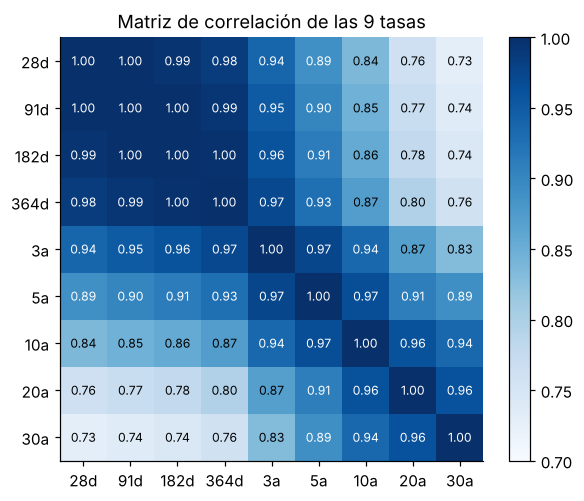

Correlación mínima: 0.73
En cambios mensuales, C28 vs C364: 0.67 (en niveles: 0.985 )


In [5]:
C = W.corr()   # Pearson por parejas
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(C, cmap="Blues", vmin=.7, vmax=1)
for i in range(9):
    for j in range(9):
        ax.text(j, i, f"{C.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if C.iloc[i, j] > .88 else "black")
ax.set_xticks(range(9), LAB); ax.set_yticks(range(9), LAB); ax.grid(False)
ax.set_title("Matriz de correlación de las 9 tasas"); plt.colorbar(im, fraction=.046); plt.show()

print("Correlación mínima:", round(C.values.min(), 2))
print("En cambios mensuales, C28 vs C364:", round(W.diff().corr().loc["C28", "C364"], 2), "(en niveles:", round(C.loc["C28", "C364"], 3), ")")

## Paso 3 · Imputación
### 3.1 Tres métodos
Los tres se aplican solo con los datos disponibles hasta cada fecha, así que ninguno usa información futura. `ultimo_valor` no es un método candidato: se usa para el baseline (la última subasta realmente observada).

In [6]:
def imp_lineal(X):
    """Interpolación lineal en el tiempo. Un hueco al final de la ventana no tiene dato posterior y toma el último valor."""
    return pd.DataFrame(X).interpolate(method="linear", limit_area="inside").ffill().bfill().to_numpy(copy=True)

def imp_knn(X, k=5):
    """KNN: promedio del plazo faltante en los k meses más parecidos."""
    return KNNImputer(n_neighbors=k, weights="distance").fit_transform(X)

def imp_mice(X):
    """MICE: regresiones encadenadas con las otras tasas."""
    return IterativeImputer(max_iter=25, tol=1e-4, random_state=0).fit_transform(X)

def ultimo_valor(X):
    return pd.DataFrame(X).ffill().bfill().to_numpy(copy=True)

IMPUTADORES = {"MICE": imp_mice, "KNN": imp_knn, "Interpolación lineal": imp_lineal}

### 3.2 Evaluación: oculto subastas reales y mido el error al recuperarlas
- **Huecos al azar:** oculto 10% de las subastas observadas de los bonos, 20 repeticiones.
- **Último mes:** en cada fecha desde sep-2014 oculto la subasta del mes más reciente, que es la situación real al pronosticar.

In [7]:
rng = np.random.default_rng(0)
obs = [(t, i) for t in range(len(X)) for i in range(4, 9) if not np.isnan(X[t, i])]
err = {m: [] for m in IMPUTADORES}
for rep in range(20):
    idx = rng.choice(len(obs), size=int(.10 * len(obs)), replace=False)
    Xm = X.copy()
    for j in idx: Xm[obs[j]] = np.nan
    for m, f in IMPUTADORES.items():
        Z = f(Xm)
        err[m] += [Z[obs[j]] - X[obs[j]] for j in idx]

err_ult = {m: [] for m in IMPUTADORES}
for t in range(FIRST_ORIGIN, len(X)):
    for i in range(4, 9):
        if np.isnan(X[t, i]): continue
        Wm = X[:t + 1].copy(); Wm[t, i] = np.nan
        for m, f in IMPUTADORES.items():
            err_ult[m].append(f(Wm)[-1, i] - X[t, i])

rmse_pb = lambda e: 100 * np.sqrt(np.mean(np.square(e)))
tabla_imp = pd.DataFrame({"Error huecos al azar (pb)": {m: rmse_pb(e) for m, e in err.items()},
                          "Error último mes (pb)": {m: rmse_pb(e) for m, e in err_ult.items()}}).round(1)
tabla_imp

,Error huecos al azar (pb),Error último mes (pb)
MICE,34.3,34.3
KNN,34.9,36.6
Interpolación lineal,31.8,38.4


Los tres se comportan igual (entre 32 y 38 pb), así que elijo **el más simple: la interpolación lineal**, que no tiene modelo ni hiperparámetros y no usa la relación entre plazos que después mido con PCA.

## Paso 4 · Análisis de componentes principales
PCA sobre la matriz de covarianzas (sin estandarizar: las nueve series están en las mismas unidades).

Varianza explicada por componente: [94.3  4.6  0.7  0.2] | tres componentes: 99.5 %


,28d,91d,182d,364d,3a,5a,10a,20a,30a
Componente 1,0.42,0.43,0.43,0.42,0.32,0.28,0.22,0.18,0.16
Componente 2,-0.29,-0.27,-0.23,-0.15,0.17,0.34,0.43,0.46,0.47
Componente 3,-0.39,-0.20,0.00,0.21,0.54,0.40,0.01,-0.32,-0.46


Con los 40 meses completos: [92.9  5.8  0.9] | coseno entre coeficientes: [np.float64(0.9996), np.float64(0.9992), np.float64(0.9874)]
En cambios mensuales, tres componentes explican: 77.6 %


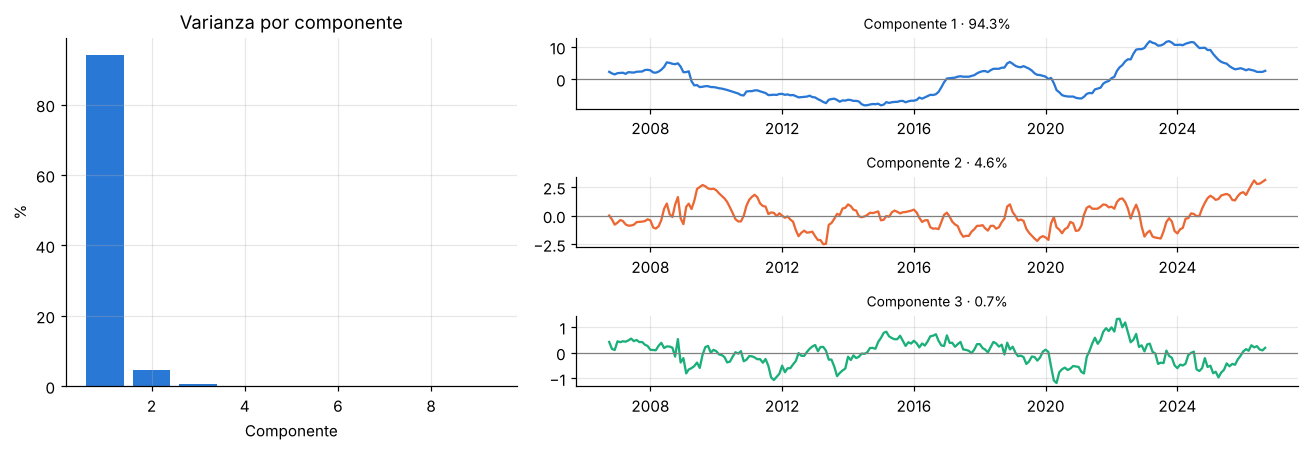

In [8]:
def pca(Z):
    """Varianza explicada y coeficientes, con signos fijados para que se lean igual siempre."""
    mu = Z.mean(0)
    _, s, Vt = np.linalg.svd(Z - mu, full_matrices=False)
    var = s ** 2 / (s ** 2).sum()
    L = Vt.T.copy()
    for j, ref in zip(range(3), [slice(None), slice(-1, None), slice(4, 6)]):
        if L[ref, j].sum() < 0: L[:, j] *= -1
    return var, L

Z = imp_lineal(X)
var, L = pca(Z)
print("Varianza explicada por componente:", (100 * var[:4]).round(1), "| tres componentes:", round(100 * var[:3].sum(), 1), "%")
display(pd.DataFrame(L[:, :3].T, index=["Componente 1", "Componente 2", "Componente 3"], columns=LAB).round(2))

# comprobación sin imputar: solo los 40 meses completos
var_cc, L_cc = pca(W.dropna().values)
print("Con los 40 meses completos:", (100 * var_cc[:3]).round(1), "| coseno entre coeficientes:", [round(abs(L[:, j] @ L_cc[:, j]), 4) for j in range(3)])
var_d, _ = pca(np.diff(Z, axis=0))
print("En cambios mensuales, tres componentes explican:", round(100 * var_d[:3].sum(), 1), "%")

F = (Z - Z.mean(0)) @ L[:, :3]
fig = plt.figure(figsize=(12, 4.2)); gs = fig.add_gridspec(3, 2, width_ratios=[1, 1.6])
a0 = fig.add_subplot(gs[:, 0]); a0.bar(range(1, 10), 100 * var, color=BLUE); a0.set_title("Varianza por componente"); a0.set_xlabel("Componente"); a0.set_ylabel("%")
axs = [fig.add_subplot(gs[j, 1]) for j in range(3)]
for j, (a, c) in enumerate(zip(axs, [BLUE, ORANGE, GREEN])):
    a.plot(W.index, F[:, j], color=c); a.axhline(0, color="gray", lw=.8); a.set_title(f"Componente {j+1} · {100*var[j]:.1f}%", fontsize=9)
plt.tight_layout(); plt.show()

## Paso 5 · Dos enfoques
- **Individual:** las 9 series originales, cada una con su propio modelo.
- **Colectivo:** los 3 componentes principales; se pronostican y con sus coeficientes se reconstruyen las 9 tasas.

En cada fecha del backtest la imputación y el PCA se rehacen solo con los datos disponibles hasta ese mes.

In [9]:
def factorizar(Xobs, k=3):
    """Imputa con interpolación lineal y hace PCA. Devuelve matriz completa, medias, coeficientes y componentes."""
    Z = imp_lineal(Xobs)
    mu = Z.mean(0)
    _, _, Vt = np.linalg.svd(Z - mu, full_matrices=False)
    L = Vt[:k].T
    return Z, mu, L, (Z - mu) @ L

## Paso 6 · Modelos
- **Suavizamiento — Holt** con tendencia amortiguada (Holt-Winters sin componente estacional): el método clásico más simple.
- **Estadístico — ARIMA**, orden elegido por BIC con los datos previos al periodo de evaluación.
- **Machine learning — Ridge**: regresión directa del cambio a *h* meses sobre los últimos 3 valores; la penalización se elige por validación cruzada.
- **Baseline:** caminata aleatoria (la tasa se queda en su último valor subastado).
- **Referencia:** VAR sobre los 3 componentes, con rezagos por BIC (los componentes se pronostican entre sí).

In [10]:
# comprobación de que no hay estacionalidad: ANOVA del cambio mensual por mes del año
p_est = {s: stats.f_oneway(*[g.dropna() for _, g in W[s].diff().groupby(W.index.month)]).pvalue for s in S}
print("Valores p de estacionalidad:", {k: round(v, 2) for k, v in p_est.items()})

def holt(y, n=12):
    return np.asarray(ExponentialSmoothing(y, trend="add", damped_trend=True, initialization_method="estimated").fit().forecast(n))

def arima(y, order, n=12):
    return np.asarray(ARIMA(y, order=order, trend="c" if order[1] == 0 else "n").fit().forecast(n))

def elegir_orden(y):
    best = (np.inf, (1, 1, 0))
    for p in range(3):
        for d in range(2):
            for q in range(3):
                try:
                    best = min(best, (ARIMA(y, order=(p, d, q), trend="c" if d == 0 else "n").fit().bic, (p, d, q)))
                except Exception:
                    pass
    return best[1]

ALPHAS, NLAGS = np.logspace(-3, 3, 13), 3
def ridge_directo(Y, Xf, h):
    """Pronóstico directo a h pasos: cambio de cada columna de Y sobre los últimos 3 valores de Xf."""
    T = len(Y)
    feats = np.column_stack([Xf[NLAGS - 1 - k: T - k] for k in range(NLAGS)])
    Fz = (feats - feats.mean(0)) / (feats.std(0) + 1e-12)
    s_idx = np.arange(NLAGS - 1, T); tr = s_idx + h <= T - 1
    out = np.empty(Y.shape[1])
    for j in range(Y.shape[1]):
        m = RidgeCV(alphas=ALPHAS).fit(Fz[tr], Y[s_idx[tr] + h, j] - Y[s_idx[tr], j])
        out[j] = Y[-1, j] + m.predict(Fz[-1:])[0]
    return out

def var_fit(Sx, p, start=None):
    start = p if start is None else start
    T = len(Sx); Y = Sx[start:]
    R = np.column_stack([np.ones(T - start)] + [Sx[start - k:T - k] for k in range(1, p + 1)])
    Cf = np.linalg.lstsq(R, Y, rcond=None)[0]
    return Cf, Y - R @ Cf

def var_pronostico(Sx, h, pmax=4):
    k, best = Sx.shape[1], (np.inf, 1)
    for p in range(1, pmax + 1):
        _, E = var_fit(Sx, p, start=pmax); n = len(E)
        best = min(best, (np.log(np.linalg.det(E.T @ E / n)) + np.log(n) / n * (p * k * k + k), p))
    p = best[1]; Cf, _ = var_fit(Sx, p)
    hist = [Sx[-k] for k in range(1, p + 1)]
    for _ in range(h):
        hist = [np.r_[1, np.concatenate(hist)] @ Cf] + hist[:-1]
    return hist[0]

# órdenes ARIMA elegidos solo con la ventana inicial (antes del primer pronóstico evaluado)
Z0, _, _, F0 = factorizar(X[:FIRST_ORIGIN + 1])
ORD9 = [elegir_orden(Z0[:, i]) for i in range(9)]
ORDCP = [elegir_orden(F0[:, j]) for j in range(3)]
print("Órdenes ARIMA por serie:", dict(zip(S, ORD9)))
print("Órdenes ARIMA por componente:", ORDCP)

Valores p de estacionalidad: {'C28': np.float64(0.43), 'C91': np.float64(0.63), 'C182': np.float64(0.38), 'C364': np.float64(0.43), 'M3': np.float64(0.25), 'M5': np.float64(0.05), 'M10': np.float64(0.73), 'M20': np.float64(0.45), 'M30': np.float64(0.28)}


Órdenes ARIMA por serie: {'C28': (1, 1, 1), 'C91': (0, 1, 1), 'C182': (0, 1, 1), 'C364': (0, 1, 0), 'M3': (0, 1, 0), 'M5': (0, 1, 0), 'M10': (0, 1, 1), 'M20': (0, 1, 0), 'M30': (0, 1, 0)}
Órdenes ARIMA por componente: [(0, 1, 1), (0, 1, 2), (1, 1, 0)]


## Paso 7 · Evaluación: backtest con ventana expandible
En cada fecha desde sep-2014: tapo todo lo posterior, rehago imputación, PCA y modelos con lo que queda, pronostico 3 y 12 meses adelante y comparo contra la subasta real (nunca contra un valor imputado). Mismas fechas para todos los modelos.

In [11]:
def un_origen(t):
    warnings.filterwarnings("ignore")   # los procesos en paralelo no heredan el filtro
    Xobs = X[: t + 1]
    ultimo = ultimo_valor(Xobs)[-1]
    Z, mu, L, F = factorizar(Xobs)
    rec = lambda f: mu + f @ L.T
    h9 = np.column_stack([holt(Z[:, i]) for i in range(9)]);  hp = np.column_stack([holt(F[:, j]) for j in range(3)])
    a9 = np.column_stack([arima(Z[:, i], ORD9[i]) for i in range(9)]); ap = np.column_stack([arima(F[:, j], ORDCP[j]) for j in range(3)])
    res = {}
    for h in H:
        if t + h > len(X) - 1: continue
        res[h] = {"Baseline": ultimo,
                  "Holt · 9 series": h9[h - 1], "Holt · 3 componentes": rec(hp[h - 1]),
                  "ARIMA · 9 series": a9[h - 1], "ARIMA · 3 componentes": rec(ap[h - 1]),
                  "Ridge · 9 series": np.array([ridge_directo(Z[:, [i]], Z[:, [i]], h)[0] for i in range(9)]),
                  "Ridge · 3 componentes": rec(ridge_directo(F, F, h)),
                  "Ref: VAR · 3 componentes": rec(var_pronostico(F, h))}
    return t, res

salida = Parallel(n_jobs=-1)(delayed(un_origen)(t) for t in range(FIRST_ORIGIN, len(X) - 3))
filas = [(h, W.index[t], m, s, v[i], X[t + h, i]) for t, res in salida for h, d in res.items() for m, v in d.items() for i, s in enumerate(S)]
bt = pd.DataFrame(filas, columns=["h", "origen", "modelo", "serie", "pronostico", "real"]).dropna(subset=["real"])
bt["error"] = bt.pronostico - bt.real; bt["se"] = bt.error ** 2; bt["ae"] = bt.error.abs()
print("Fechas evaluadas:", bt.groupby("h").origen.nunique().to_dict())

Fechas evaluadas: {3: 142, 12: 133}


### 7.1 Métricas: RMSE (principal), MAE (complemento) y prueba de Diebold-Mariano contra el baseline

In [12]:
def dm_test(d, h):
    """Diebold-Mariano con varianza HAC (h-1 rezagos) y corrección de Harvey-Leybourne-Newbold."""
    d = np.asarray(d, float); n = len(d); db = d.mean()
    g = [np.sum((d[k:] - db) * (d[: n - k] - db)) / n for k in range(h)]
    v = (g[0] + 2 * sum(g[1:])) / n
    dm = db / np.sqrt(v) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return 2 * stats.t.sf(abs(dm), n - 1)

MODELOS = list(dict.fromkeys(bt.modelo))
def tabla(h):
    g = bt[bt.h == h]; base = g[g.modelo == "Baseline"]
    pc = g.pivot_table(index="origen", columns="modelo", values="se", aggfunc="mean")   # pérdida de la curva por fecha
    filas = {}
    for m in MODELOS:
        x = g[g.modelo == m]
        filas[m] = {"RMSE": np.sqrt(x.se.mean()), "MAE": x.ae.mean(), "RMSE vs. baseline": np.sqrt(x.se.mean() / base.se.mean()),
                    "CETES": np.sqrt(x[x.serie.isin(CETES)].se.mean() / base[base.serie.isin(CETES)].se.mean()),
                    "MBONOS": np.sqrt(x[x.serie.isin(MBONOS)].se.mean() / base[base.serie.isin(MBONOS)].se.mean()),
                    "Valor p": np.nan if m == "Baseline" else dm_test((pc[m] - pc["Baseline"]).values, h)}
    return pd.DataFrame(filas).T.round(3)

print("A 3 meses"); display(tabla(3))
print("A 12 meses"); display(tabla(12))

A 3 meses


,RMSE,MAE,RMSE vs. baseline,CETES,MBONOS,Valor p
Baseline,0.619,0.474,1.000,1.000,1.000,NaN
Holt · 9 series,0.538,0.407,0.869,0.708,1.012,0.006
Holt · 3 componentes,0.542,0.407,0.876,0.773,0.973,0.008
ARIMA · 9 series,0.584,0.446,0.944,0.888,1.000,0.003
ARIMA · 3 componentes,0.588,0.449,0.950,0.952,0.948,0.002
Ridge · 9 series,0.557,0.425,0.899,0.772,1.016,0.006
Ridge · 3 componentes,0.555,0.415,0.896,0.782,1.002,0.018
Ref: VAR · 3 componentes,0.559,0.419,0.902,0.787,1.011,0.027


A 12 meses


,RMSE,MAE,RMSE vs. baseline,CETES,MBONOS,Valor p
Baseline,1.806,1.406,1.000,1.000,1.000,NaN
Holt · 9 series,1.633,1.286,0.904,0.858,1.030,0.097
Holt · 3 componentes,1.634,1.287,0.905,0.882,0.968,0.098
ARIMA · 9 series,1.748,1.362,0.968,0.957,1.000,0.071
ARIMA · 3 componentes,1.772,1.378,0.981,0.983,0.977,0.010
Ridge · 9 series,1.729,1.398,0.957,0.919,1.064,0.667
Ridge · 3 componentes,1.760,1.424,0.974,0.920,1.119,0.789
Ref: VAR · 3 componentes,1.581,1.257,0.875,0.817,1.028,0.047


## Paso 8 · Resultados
### 8.1 ¿Colectivamente o individualmente?
Valor p de Diebold-Mariano de la diferencia entre 9 series y 3 componentes con el mismo modelo, y de Holt contra los demás.

In [13]:
for h in H:
    pc = bt[bt.h == h].pivot_table(index="origen", columns="modelo", values="se", aggfunc="mean")
    print(f"--- {h} meses ---")
    for m in ["Holt", "ARIMA", "Ridge"]:
        print(f"  {m}: 9 series vs 3 componentes  p = {dm_test((pc[f'{m} · 9 series'] - pc[f'{m} · 3 componentes']).values, h):.2f}")
    for m in ["ARIMA · 9 series", "Ridge · 9 series", "Ref: VAR · 3 componentes"]:
        print(f"  Holt · 9 series vs {m}  p = {dm_test((pc['Holt · 9 series'] - pc[m]).values, h):.2f}")

--- 3 meses ---
  Holt: 9 series vs 3 componentes  p = 0.75
  ARIMA: 9 series vs 3 componentes  p = 0.67
  Ridge: 9 series vs 3 componentes  p = 0.91
  Holt · 9 series vs ARIMA · 9 series  p = 0.01
  Holt · 9 series vs Ridge · 9 series  p = 0.20
  Holt · 9 series vs Ref: VAR · 3 componentes  p = 0.34


--- 12 meses ---
  Holt: 9 series vs 3 componentes  p = 0.98
  ARIMA: 9 series vs 3 componentes  p = 0.23
  Ridge: 9 series vs 3 componentes  p = 0.76
  Holt · 9 series vs ARIMA · 9 series  p = 0.11
  Holt · 9 series vs Ridge · 9 series  p = 0.62
  Holt · 9 series vs Ref: VAR · 3 componentes  p = 0.42


### 8.2 ¿Dónde está la mejora? Error relativo al baseline por plazo

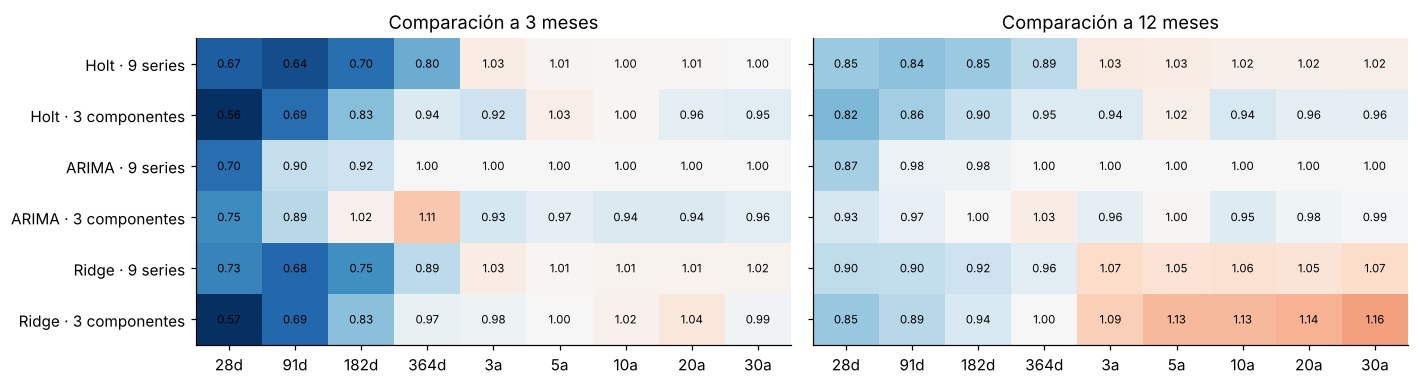

Autocorrelación de los cambios mensuales: {'C28': 0.58, 'C91': 0.63, 'C182': 0.56, 'C364': 0.37, 'M3': 0.11, 'M5': -0.08, 'M10': -0.29, 'M20': -0.19, 'M30': -0.1}


In [14]:
rel = (bt.groupby(["h", "modelo", "serie"]).se.mean().pow(.5).unstack("serie")[S])
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
mods = [m for m in MODELOS if m not in ("Baseline", "Ref: VAR · 3 componentes")]
for a, h in zip(ax, H):
    R = rel.loc[h].loc[mods] / rel.loc[h].loc["Baseline"]
    im = a.imshow(R.values, cmap="RdBu_r", vmin=.6, vmax=1.4, aspect="auto")
    for i in range(R.shape[0]):
        for j in range(R.shape[1]):
            a.text(j, i, f"{R.values[i, j]:.2f}", ha="center", va="center", fontsize=7.5)
    a.set_xticks(range(9), LAB); a.set_yticks(range(len(mods)), mods); a.grid(False); a.set_title(f"Comparación a {h} meses")
plt.tight_layout(); plt.show()

# por qué funciona en CETES: inercia en los cambios mensuales
print("Autocorrelación de los cambios mensuales:", W.diff().apply(lambda s: s.autocorr(1)).round(2).to_dict())

## Paso 9 · Pronóstico final con Holt (9 series)
Entrenado con todos los datos hasta septiembre de 2026, con un pronóstico por mes. Bandas: cuantiles 10 y 90 de los errores del propio modelo en el backtest.

,C28,C91,C182,C364,M3,M5,M10,M20,M30
Último dato (baseline),6.29,6.59,6.82,7.13,8.24,9.00,9.35,9.64,9.87
"Dic-2026, Holt",6.29,6.66,6.86,7.13,8.24,8.98,9.32,9.64,9.87
"Dic-2026, banda 10%",5.77,6.22,6.38,6.46,7.47,8.38,8.77,9.13,9.39
"Dic-2026, banda 90%",6.83,7.15,7.40,7.74,9.17,9.86,10.15,10.46,10.70
"Sep-2027, Holt",6.29,6.76,6.93,7.12,8.24,8.98,9.32,9.64,9.86
"Sep-2027, banda 10%",3.73,4.35,4.42,4.78,6.02,7.32,8.09,8.80,8.91
"Sep-2027, banda 90%",9.13,9.57,9.71,10.26,10.67,11.03,11.27,10.99,11.03


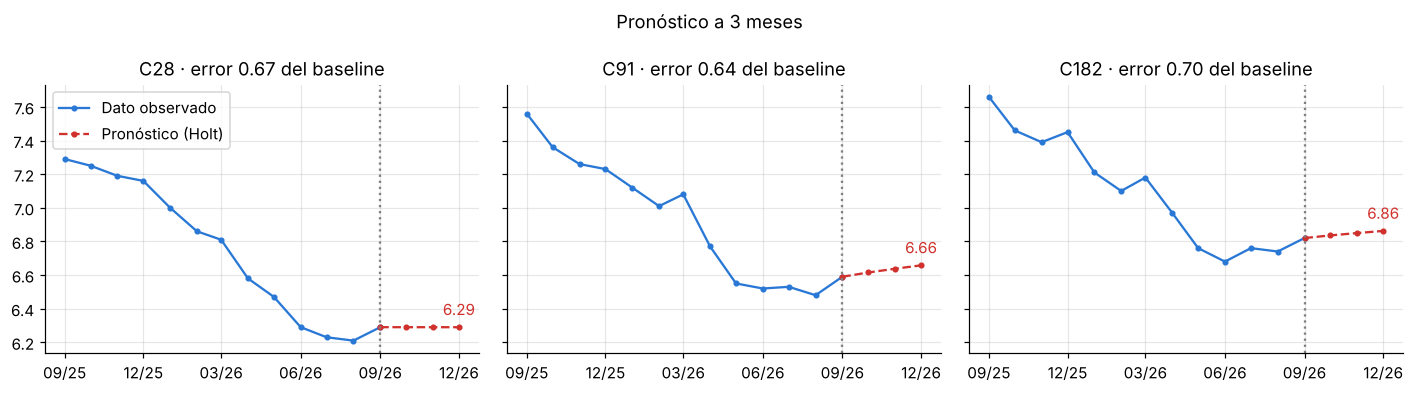

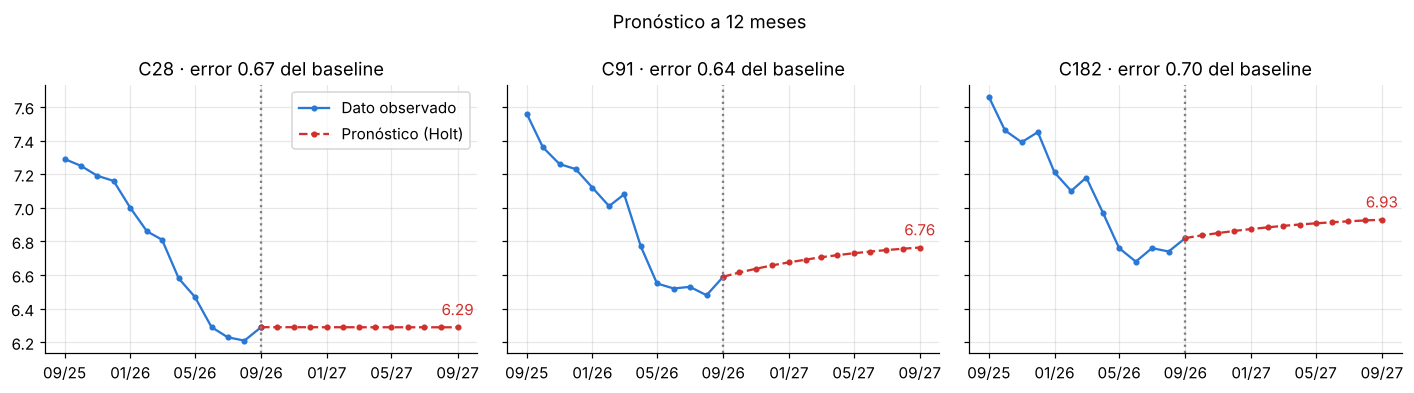

In [15]:
Zfull = imp_lineal(X)
ultimo = ultimo_valor(X)[-1]
camino = np.column_stack([holt(Zfull[:, i]) for i in range(9)])     # 12 meses x 9 plazos
fechas = pd.date_range(W.index[-1], periods=13, freq="MS")[1:]

filas = {"Último dato (baseline)": ultimo}
for h, nombre in [(3, "Dic-2026"), (12, "Sep-2027")]:
    q = bt[(bt.h == h) & (bt.modelo == "Holt · 9 series")].groupby("serie").error.quantile([.1, .9]).unstack().loc[S]
    filas[f"{nombre}, Holt"] = camino[h - 1]
    filas[f"{nombre}, banda 10%"] = camino[h - 1] - q[.9].values
    filas[f"{nombre}, banda 90%"] = camino[h - 1] - q[.1].values
display(pd.DataFrame(filas, index=S).T.round(2))

# gráficas a 3 y 12 meses en los tres plazos donde Holt funcionó mejor en el backtest
for n, titulo in [(3, "Pronóstico a 3 meses"), (12, "Pronóstico a 12 meses")]:
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
    for a, i in zip(ax, (0, 1, 2)):
        hist = W.iloc[:, i].loc["2025-09-01":]
        a.plot(hist.index, hist, color=BLUE, marker="o", ms=3, label="Dato observado")
        a.plot([W.index[-1]] + list(fechas[:n]), np.r_[hist.iloc[-1], camino[:n, i]], color=RED, ls="--", marker="o", ms=3, label="Pronóstico (Holt)")
        a.annotate(f"{camino[n-1, i]:.2f}", (fechas[n - 1], camino[n - 1, i]), xytext=(0, 8), textcoords="offset points", ha="center", color=RED)
        a.xaxis.set_major_locator(mdates.MonthLocator(interval=4 if n == 12 else 3)); a.xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
        a.axvline(W.index[-1], color="gray", ls=":"); a.set_title(f"{S[i]} · error {rel.loc[3].loc['Holt · 9 series', S[i]] / rel.loc[3].loc['Baseline', S[i]]:.2f} del baseline")
    ax[0].legend(); fig.suptitle(titulo); plt.tight_layout(); plt.show()

## Conclusiones
1. **¿Hay estructura?** Sí. Tres componentes principales explican 99.5% de la varianza de las nueve tasas; con los 40 meses completos, sin imputar, sale lo mismo.
2. **¿Se puede pronosticar?** Sí, mejor que el baseline: Holt reduce el error 13% a un trimestre (p = 0.006) y 10% a cuatro (p = 0.10, no concluyente). Toda la mejora está en los CETES, cuyos cambios tienen inercia porque Banxico mueve su tasa en pasos sucesivos.
3. **¿La estructura mejora el pronóstico?** No. Pronosticar los 3 componentes da el mismo error que las 9 series, con los tres modelos; tampoco mejora un VAR donde los componentes se pronostican entre sí.

**Siguientes pasos:** variables exógenas (tasa objetivo de Banxico, inflación), un enfoque de deep learning (LSTM), un análisis más económico del problema, tasas forward como rival y un modelo en espacio de estados.